# **MÓDULO 43 - Projeto Final: Prevendo a vitória em partidas ranqueadas de League of Legends**

# 1. Definição do problema

**Base escolhida:** `LOL_RANKED_WIN` (partidas ranqueadas de League of Legends). Escolhi essa base por três motivos: as classes são balanceadas (a acurácia é uma métrica válida), cada linha é uma partida independente e o problema tem uma pergunta de negócio clara. Ela também esconde uma armadilha estrutural (colunas redundantes entre os times azul e vermelho) que precisa ser tratada para a modelagem ser feita corretamente.

**Problema de negócio:** uma plataforma de e-sports, um time ou um comentarista quer saber, logo nos **10 primeiros minutos** de uma partida, qual time tem mais chance de vencer. Essa previsão permite mostrar a probabilidade de vitória ao vivo, ajudar o treinador a decidir quando arriscar ou jogar com segurança e identificar quais vantagens iniciais realmente pesam no resultado.

**Tarefa de Machine Learning:** classificação binária supervisionada.

**Variável-alvo:** `blueWins` (1 = o time azul venceu, 0 = o time vermelho venceu).

**Métricas:** como as classes são equilibradas, uso a acurácia junto com o ROC-AUC, a matriz de confusão e o F1-score, que mostram se o modelo erra de forma equilibrada para os dois lados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, classification_report, confusion_matrix, RocCurveDisplay
from sklearn.inspection import permutation_importance
from IPython.display import display
from xgboost import XGBClassifier

# 2. Carga e verificações iniciais

In [2]:
df = pd.read_csv('../data/Base_M43_Pratique_LOL_RANKED_WIN.csv')
df.shape

(9879, 40)

In [3]:
df.head()

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,...,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,...,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,...,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,...,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,...,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


In [4]:
df.dtypes.value_counts()

int64      34
float64     6
Name: count, dtype: int64

In [5]:
df.isnull().sum().sum(), df.duplicated().sum(), df['gameId'].duplicated().sum()

(np.int64(0), np.int64(0), np.int64(0))

A base tem **9.879 partidas e 40 colunas**, todas numéricas. Não há valores ausentes, linhas duplicadas nem `gameId` repetido. Todas as colunas são medidas **até o minuto 10** da partida, e o alvo (`blueWins`) é o resultado final, então não existe vazamento do futuro nas variáveis originais. A coluna `gameId` é só um identificador e não tem valor preditivo.

# 3. Análise Exploratória de Dados (EDA)

### Técnica 1: distribuição da variável-alvo

In [6]:
df['blueWins'].value_counts(normalize=True).round(3)

blueWins
0    0.501
1    0.499
Name: proportion, dtype: float64

As classes estão praticamente equilibradas (50,1% de derrotas e 49,9% de vitórias do time azul). Não preciso de técnicas de balanceamento e a acurácia é uma métrica confiável.

### Técnica 2: estatísticas descritivas e outliers

In [7]:
df[['blueWardsPlaced', 'blueKills', 'blueTotalGold', 'blueGoldDiff', 'blueExperienceDiff']].describe().round(1)

,blueWardsPlaced,blueKills,blueTotalGold,blueGoldDiff,blueExperienceDiff
count,9879.0,9879.0,9879.0,9879.0,9879.0
mean,22.3,6.2,16503.5,14.4,-33.6
std,18.0,3.0,1535.4,2453.3,1920.4
min,5.0,0.0,10730.0,-10830.0,-9333.0
25%,14.0,4.0,15415.5,-1585.5,-1290.5
50%,16.0,6.0,16398.0,14.0,-28.0
75%,20.0,8.0,17459.0,1596.0,1212.0
max,250.0,22.0,23701.0,11467.0,8348.0


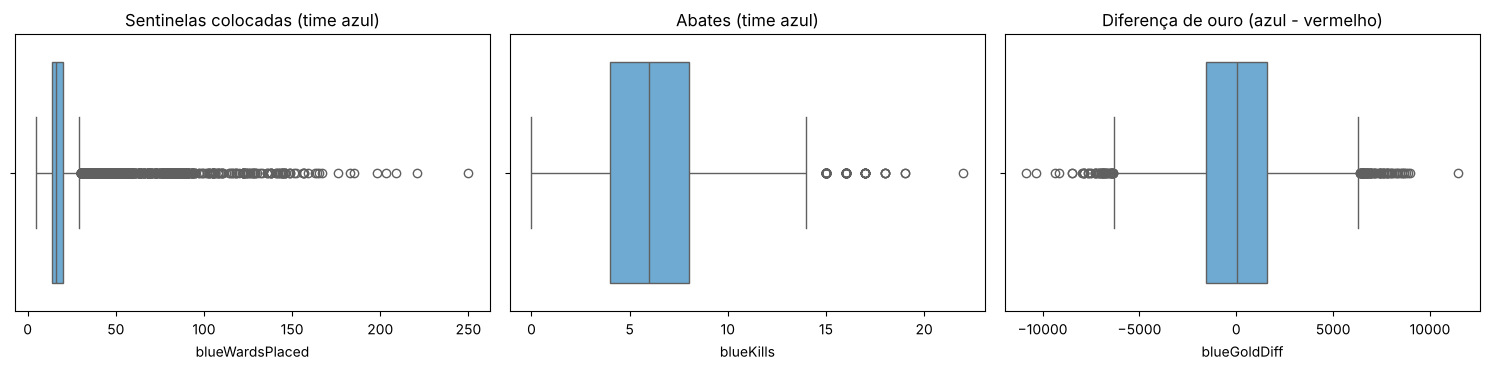

Partidas com mais de 100 sentinelas: 108 | assimetria: 4.14


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=df['blueWardsPlaced'], ax=axes[0], color='#5DADE2'); axes[0].set_title('Sentinelas colocadas (time azul)')
sns.boxplot(x=df['blueKills'], ax=axes[1], color='#5DADE2'); axes[1].set_title('Abates (time azul)')
sns.boxplot(x=df['blueGoldDiff'], ax=axes[2], color='#5DADE2'); axes[2].set_title('Diferença de ouro (azul - vermelho)')
plt.tight_layout(); plt.show()
print('Partidas com mais de 100 sentinelas:', (df['blueWardsPlaced'] > 100).sum(), '| assimetria:', round(df['blueWardsPlaced'].skew(), 2))

`blueWardsPlaced` é muito assimétrica (assimetria 4,1): a mediana é 16 sentinelas, mas há 108 partidas com mais de 100 e um máximo de 250. Não são valores impossíveis (alguns jogadores colocam muitas sentinelas), e essa variável tem pouca relação com o resultado (mostro isso adiante), então **mantenho os valores** e uso padronização na regressão logística. As diferenças de ouro e de abates têm distribuição simétrica, centrada perto de zero.

### Técnica 3: distribuição das variáveis principais por resultado

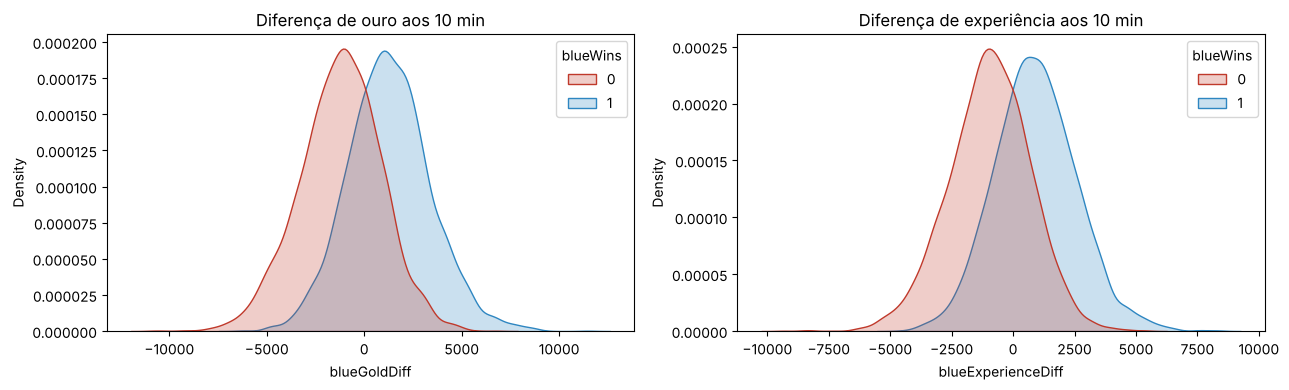

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in zip(axes, ['blueGoldDiff', 'blueExperienceDiff'], ['Diferença de ouro aos 10 min', 'Diferença de experiência aos 10 min']):
    sns.kdeplot(data=df, x=col, hue='blueWins', fill=True, common_norm=False, palette={0: '#C0392B', 1: '#2E86C1'}, ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

As partidas vencidas pelo time azul concentram diferenças positivas de ouro e de experiência, e as perdidas concentram diferenças negativas. As duas curvas se sobrepõem bastante na região central, o que já indica que a vantagem nos 10 minutos ajuda, mas **não decide sozinha** o jogo.

### Técnica 4: correlação das variáveis com o resultado

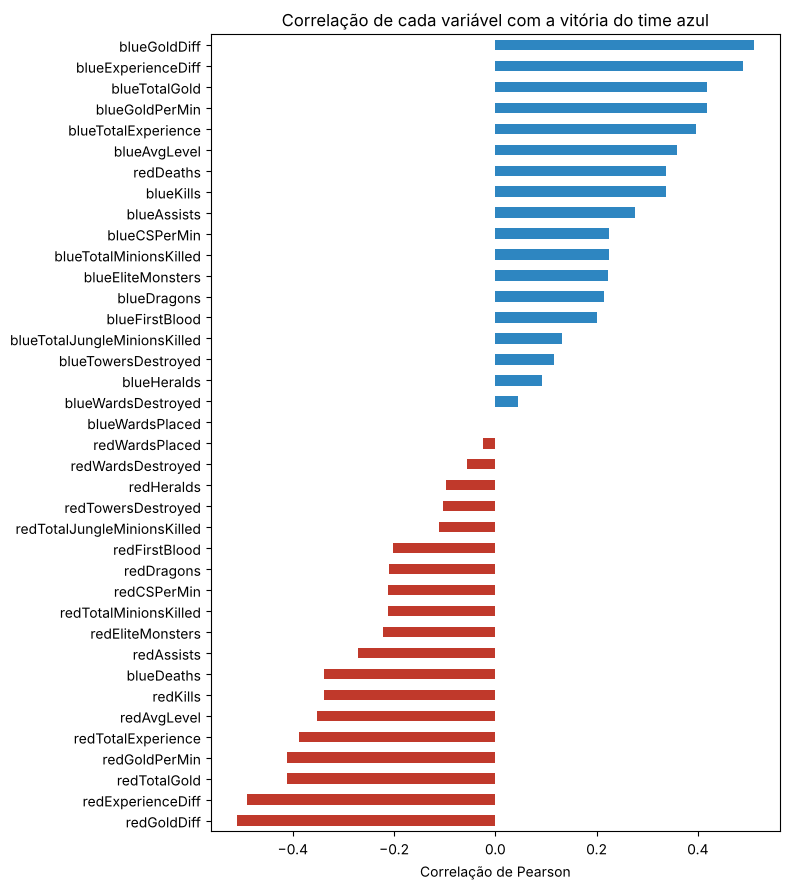

In [10]:
corr_alvo = df.drop(columns=['gameId']).corr()['blueWins'].drop('blueWins').sort_values()
plt.figure(figsize=(8, 9))
corr_alvo.plot(kind='barh', color=['#C0392B' if v < 0 else '#2E86C1' for v in corr_alvo.values])
plt.title('Correlação de cada variável com a vitória do time azul'); plt.xlabel('Correlação de Pearson')
plt.tight_layout(); plt.show()

As variáveis mais ligadas à vitória do azul são a **diferença de ouro (0,51)** e a **diferença de experiência (0,49)**, seguidas pelos abates (0,34), dragões (0,21) e primeiro abate (0,20). As variáveis do time vermelho aparecem com o sinal contrário, como esperado. Sentinelas colocadas e destruídas têm correlação próxima de zero.

### Técnica 5: redundância entre as colunas (armadilha estrutural da base)

In [11]:
corr = df.drop(columns=['gameId', 'blueWins']).corr()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pares[pares.abs() > 0.999].round(3)

blueFirstBlood          redFirstBlood       -1.0
blueKills               redDeaths            1.0
blueDeaths              redKills             1.0
blueTotalGold           blueGoldPerMin       1.0
blueTotalMinionsKilled  blueCSPerMin         1.0
blueGoldDiff            redGoldDiff         -1.0
blueExperienceDiff      redExperienceDiff   -1.0
redTotalGold            redGoldPerMin        1.0
redTotalMinionsKilled   redCSPerMin          1.0
dtype: float64

In [12]:
print('redGoldDiff = -blueGoldDiff:', (df['redGoldDiff'] == -df['blueGoldDiff']).all())
print('redExperienceDiff = -blueExperienceDiff:', (df['redExperienceDiff'] == -df['blueExperienceDiff']).all())
print('redKills = blueDeaths:', (df['redKills'] == df['blueDeaths']).all())
print('redDeaths = blueKills:', (df['redDeaths'] == df['blueKills']).all())
print('redFirstBlood = 1 - blueFirstBlood:', (df['redFirstBlood'] == 1 - df['blueFirstBlood']).all())
print('blueGoldDiff = blueTotalGold - redTotalGold:', (df['blueGoldDiff'] == df['blueTotalGold'] - df['redTotalGold']).all())
print('blueEliteMonsters = blueDragons + blueHeralds:', (df['blueEliteMonsters'] == df['blueDragons'] + df['blueHeralds']).all())

redGoldDiff = -blueGoldDiff: True
redExperienceDiff = -blueExperienceDiff: True
redKills = blueDeaths: True
redDeaths = blueKills: True
redFirstBlood = 1 - blueFirstBlood: True
blueGoldDiff = blueTotalGold - redTotalGold: True
blueEliteMonsters = blueDragons + blueHeralds: True


**Armadilha estrutural encontrada:** a base mostra a mesma partida duas vezes, uma vez do ponto de vista do time azul e outra do vermelho, então **11 colunas são cópias exatas ou cálculos diretos de outras**:

- `redGoldDiff` e `redExperienceDiff` são o negativo das diferenças do azul;
- `redKills` é igual a `blueDeaths` e `redDeaths` é igual a `blueKills`;
- `redFirstBlood` é igual a `1 - blueFirstBlood`;
- `blueGoldPerMin`, `redGoldPerMin`, `blueCSPerMin` e `redCSPerMin` são o total dividido por 10;
- `blueEliteMonsters` e `redEliteMonsters` são a soma de dragões e arautos;
- além disso, `blueGoldDiff` é exatamente `blueTotalGold - redTotalGold` (o mesmo vale para a experiência).

Se eu usasse todas as colunas, a regressão logística teria multicolinearidade perfeita (coeficientes instáveis, sem interpretação possível) e a importância das variáveis ficaria dividida entre colunas que carregam a mesma informação. A solução está na preparação dos dados: transformar cada par azul/vermelho em **uma única variável de diferença**.

### Técnica 6: taxa de vitória por evento do jogo

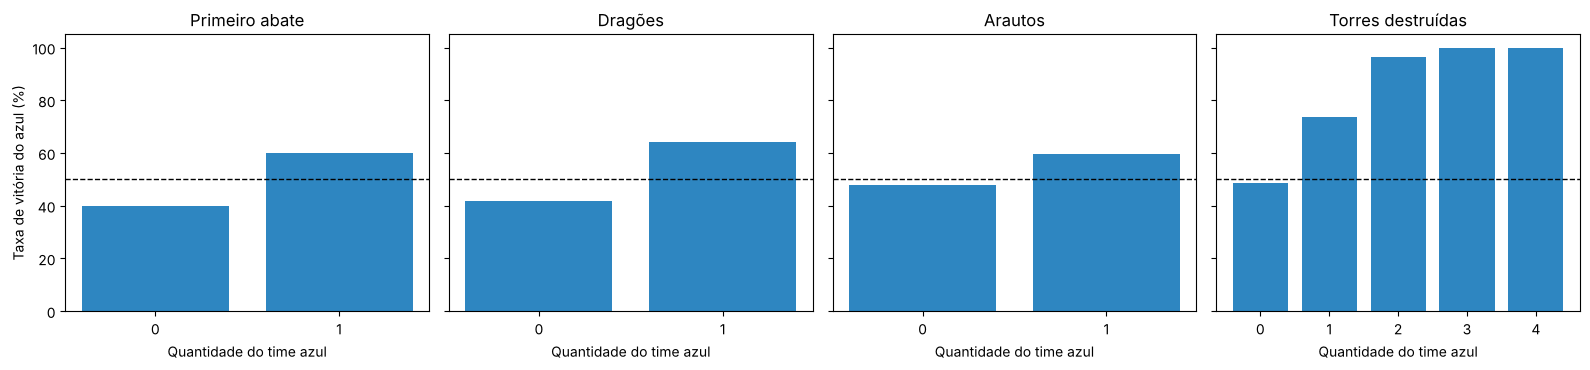

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col, title in zip(axes, ['blueFirstBlood', 'blueDragons', 'blueHeralds', 'blueTowersDestroyed'],
                          ['Primeiro abate', 'Dragões', 'Arautos', 'Torres destruídas']):
    taxa = df.groupby(col)['blueWins'].mean() * 100
    ax.bar(taxa.index.astype(str), taxa.values, color='#2E86C1')
    ax.axhline(50, color='black', linestyle='--', linewidth=1)
    ax.set_title(title); ax.set_xlabel('Quantidade do time azul')
axes[0].set_ylabel('Taxa de vitória do azul (%)')
plt.tight_layout(); plt.show()

Os eventos do jogo mudam bastante a chance de vitória: quem faz o **primeiro abate vence 59,9%** das partidas (contra 39,7% de quem não faz), quem pega o **dragão vence 64,1%** (contra 41,9%) e quem derruba **uma torre antes dos 10 minutos vence 73,7%** (mas isso acontece em só 429 das 9.879 partidas). Os arautos têm efeito menor (59,5% contra 47,7%).

### Técnica 7: testes estatísticos

In [14]:
venceu = df['blueWins'] == 1
linhas = []
for col in ['blueGoldDiff', 'blueExperienceDiff', 'blueKills', 'blueAssists', 'blueTotalMinionsKilled', 'blueWardsPlaced', 'blueWardsDestroyed']:
    a, b = df.loc[venceu, col], df.loc[~venceu, col]
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    linhas.append({'variavel': col, 'p_valor (Mann-Whitney)': stats.mannwhitneyu(a, b).pvalue, 'tamanho_do_efeito (Cohen d)': round(d, 2)})
for col in ['blueFirstBlood', 'blueDragons', 'blueHeralds']:
    linhas.append({'variavel': col, 'p_valor (Mann-Whitney)': stats.chi2_contingency(pd.crosstab(df[col], df['blueWins']))[1], 'tamanho_do_efeito (Cohen d)': np.nan})
pd.DataFrame(linhas).set_index('variavel')

,p_valor (Mann-Whitney),tamanho_do_efeito (Cohen d)
variavel,,
blueGoldDiff,0.000000e+00,1.19
blueExperienceDiff,0.000000e+00,1.12
blueKills,3.395100e-243,0.72
blueAssists,3.975948e-170,0.58
blueTotalMinionsKilled,1.017855e-106,0.46
blueWardsPlaced,1.186084e-05,0.00
blueWardsDestroyed,5.354053e-08,0.09
blueFirstBlood,2.763610e-89,NaN
blueDragons,5.481573e-100,NaN


A tabela mostra o teste de Mann-Whitney (variáveis numéricas) e o qui-quadrado (variáveis binárias, na coluna do p-valor) para checar se a variável difere entre vitórias e derrotas. Quase tudo é estatisticamente significativo, mas **com 9.879 partidas até diferenças minúsculas dão p-valor baixo**. Por isso olho também o tamanho do efeito (Cohen d): ouro (1,2) e experiência (1,1) têm efeito **grande**, abates (0,7) e assistências (0,6) têm efeito médio, e sentinelas colocadas, apesar de significativas (p = 0,00001), têm efeito praticamente nulo (d = 0,00). Significância estatística não é o mesmo que relevância prática.

### Técnica 8: taxa de vitória por faixa de vantagem de ouro

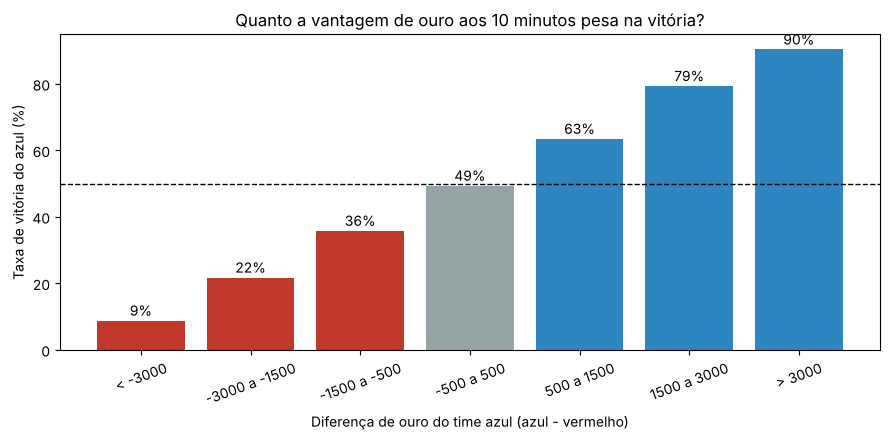

In [15]:
faixas = pd.cut(df['blueGoldDiff'], [-20000, -3000, -1500, -500, 500, 1500, 3000, 20000],
                labels=['< -3000', '-3000 a -1500', '-1500 a -500', '-500 a 500', '500 a 1500', '1500 a 3000', '> 3000'])
taxa_ouro = df.groupby(faixas)['blueWins'].agg(['mean', 'size'])
plt.figure(figsize=(9, 4.5))
plt.bar(taxa_ouro.index.astype(str), taxa_ouro['mean'] * 100, color=['#C0392B'] * 3 + ['#95A5A6'] + ['#2E86C1'] * 3)
for i, v in enumerate(taxa_ouro['mean'] * 100): plt.text(i, v + 1.5, f'{v:.0f}%', ha='center')
plt.axhline(50, color='black', linestyle='--', linewidth=1)
plt.title('Quanto a vantagem de ouro aos 10 minutos pesa na vitória?')
plt.xlabel('Diferença de ouro do time azul (azul - vermelho)'); plt.ylabel('Taxa de vitória do azul (%)')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## Principais insights da EDA

1. **A base é limpa e equilibrada**: sem ausentes ou duplicados e com 50/50 de vitórias, então a acurácia é uma métrica válida.
2. **A armadilha da base é a redundância**: 11 colunas são cópias ou cálculos exatos de outras (espelhamento azul/vermelho, soma de dragões e arautos e médias por minuto). Elas precisam ser unificadas antes da modelagem.
3. **O ouro é o fator dominante**: a diferença de ouro aos 10 minutos tem a maior correlação com a vitória (0,51) e efeito grande no teste estatístico. Estar mais de 3000 de ouro à frente significa 90% de vitória, e estar mais de 3000 atrás significa 9%.
4. **A experiência anda junto com o ouro** (correlação 0,49), mas as duas vantagens se misturam, já que quem abate mais ganha as duas coisas.
5. **Objetivos importam**: primeiro abate, dragão e torre mudam a taxa de vitória em 20 a 25 pontos percentuais. Arautos, abates isolados e sentinelas têm efeito bem menor.
6. **Sentinelas têm efeito praticamente nulo** apesar do p-valor baixo, um exemplo de significância sem relevância prática.
7. **O jogo não está decidido aos 10 minutos**: mesmo com uma vantagem de 1500 a 3000 de ouro, 21% das partidas são perdidas. Isso indica que o desempenho do modelo terá um teto.

# 4. Preparação dos dados

Passos:

1. Remover `gameId` (identificador).
2. Resolver a redundância: criar **uma variável de diferença (azul - vermelho)** para cada estatística e remover as colunas espelhadas e as médias por minuto. O resultado são 12 diferenças + `blueFirstBlood` (o primeiro abate já resume as duas colunas).
3. Não há valores ausentes nem variáveis categóricas: todas as colunas já são numéricas, então não é necessário encoding. A tipagem está correta (inteiros e decimais).
4. Separar treino e teste **antes de padronizar**. As diferenças são calculadas linha a linha, sem usar informação de outras partidas, então criá-las antes da separação não gera vazamento. Já a padronização (`StandardScaler`) usa média e desvio padrão e por isso fica dentro de um `Pipeline`, ajustada só com os dados de treino.

In [16]:
X = pd.DataFrame({
    'GoldDiff': df['blueGoldDiff'],
    'ExpDiff': df['blueExperienceDiff'],
    'KillsDiff': df['blueKills'] - df['redKills'],
    'AssistsDiff': df['blueAssists'] - df['redAssists'],
    'DragonsDiff': df['blueDragons'] - df['redDragons'],
    'HeraldsDiff': df['blueHeralds'] - df['redHeralds'],
    'TowersDiff': df['blueTowersDestroyed'] - df['redTowersDestroyed'],
    'MinionsDiff': df['blueTotalMinionsKilled'] - df['redTotalMinionsKilled'],
    'JungleDiff': df['blueTotalJungleMinionsKilled'] - df['redTotalJungleMinionsKilled'],
    'LevelDiff': df['blueAvgLevel'] - df['redAvgLevel'],
    'WardsPlacedDiff': df['blueWardsPlaced'] - df['redWardsPlaced'],
    'WardsDestroyedDiff': df['blueWardsDestroyed'] - df['redWardsDestroyed'],
    'FirstBlood': df['blueFirstBlood'],
})
y = df['blueWins']
X.shape, X.isnull().sum().sum()

((9879, 13), np.int64(0))

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(7903, 13) (1976, 13) 0.499 0.499


In [18]:
# o modelo com todas as colunas (sem as cópias exatas) vs o conjunto com diferenças, só para mostrar o efeito da redundância
colunas_copia = ['gameId', 'blueWins', 'redGoldDiff', 'redExperienceDiff', 'redKills', 'redDeaths', 'redFirstBlood',
                 'blueEliteMonsters', 'redEliteMonsters', 'blueCSPerMin', 'redCSPerMin', 'blueGoldPerMin', 'redGoldPerMin']
X_bruto = df.drop(columns=colunas_copia)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
treino_idx = X_train.index
print('Colunas originais sem as cópias:', X_bruto.shape[1], '| diferenças:', X.shape[1])

Colunas originais sem as cópias: 27 | diferenças: 13


# 5. Modelagem

Comparo uma **regra simples** (apostar no time com mais ouro) com três modelos de classificação:

- **Regressão logística:** simples e interpretável;
- **Random Forest:** captura relações não lineares;
- **XGBoost:** boosting de árvores, geralmente o mais forte em dados tabulares.

Todos são avaliados com **validação cruzada estratificada de 5 partes** só nos dados de treino.

In [19]:
regra = ((X_train['GoldDiff'] > 0).astype(int) == y_train).mean()
print('Regra simples (aposta no time com mais ouro) - acurácia no treino:', round(regra, 4))

Regra simples (aposta no time com mais ouro) - acurácia no treino: 0.724


In [20]:
modelos = {
    'Regressão Logística': Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, eval_metric='logloss', random_state=42),
}
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=skf, scoring=['accuracy', 'roc_auc', 'f1'])
    linhas.append({'modelo': nome, 'acurácia': r['test_accuracy'].mean(), 'acurácia_desvio': r['test_accuracy'].std(),
                   'roc_auc': r['test_roc_auc'].mean(), 'f1': r['test_f1'].mean()})
pd.DataFrame(linhas).set_index('modelo').round(3)

,acurácia,acurácia_desvio,roc_auc,f1
modelo,,,,
Regressão Logística,0.737,0.012,0.812,0.736
Random Forest,0.720,0.009,0.795,0.717
XGBoost,0.729,0.016,0.807,0.726


In [21]:
# efeito da redundância: regressão logística com as colunas originais (sem as cópias exatas) vs com as diferenças
bruto_cv = cross_validate(lr, X_bruto.loc[X_train.index], y_train, cv=skf, scoring=['accuracy', 'roc_auc'])
dif_cv = cross_validate(lr, X_train, y_train, cv=skf, scoring=['accuracy', 'roc_auc'])
ouro_cv = cross_validate(lr, X_train[['GoldDiff']], y_train, cv=skf, scoring=['accuracy', 'roc_auc'])
pd.DataFrame({
    'conjunto de variáveis': ['Só GoldDiff (1 variável)', f'Colunas originais sem cópias ({X_bruto.shape[1]})', f'Diferenças ({X.shape[1]})'],
    'acurácia': [ouro_cv['test_accuracy'].mean(), bruto_cv['test_accuracy'].mean(), dif_cv['test_accuracy'].mean()],
    'roc_auc': [ouro_cv['test_roc_auc'].mean(), bruto_cv['test_roc_auc'].mean(), dif_cv['test_roc_auc'].mean()],
}).round(3).set_index('conjunto de variáveis')

,acurácia,roc_auc
conjunto de variáveis,,
Só GoldDiff (1 variável),0.725,0.803
Colunas originais sem cópias (27),0.735,0.811
Diferenças (13),0.737,0.812


A regressão logística foi o melhor modelo, com os três modelos muito próximos entre si (ROC-AUC de 0,79 a 0,81), numa diferença menor que a variação entre as partes da validação cruzada. A regra simples já acerta cerca de 72%, e **uma regressão logística só com a diferença de ouro chega a 72,5%**. Todas as outras variáveis juntas acrescentam menos de 2 pontos percentuais. As diferenças (13 variáveis) funcionam um pouco melhor que as colunas originais, com a vantagem de serem independentes entre si e interpretáveis. O próximo passo ajusta os hiperparâmetros.

# 6. Otimização de hiperparâmetros

In [22]:
buscas = {
    'Regressão Logística': GridSearchCV(
        Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))]),
        {'model__C': [0.001, 0.01, 0.1, 1, 10]}, scoring='roc_auc', cv=skf),
    'Random Forest': RandomizedSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {'n_estimators': [200, 400], 'max_depth': [3, 5, 8, None], 'min_samples_leaf': [5, 10, 20], 'max_features': ['sqrt', 0.5]},
        n_iter=15, scoring='roc_auc', cv=skf, random_state=42),
    'XGBoost': RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1),
        {'n_estimators': [100, 200, 400], 'max_depth': [2, 3, 4], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
         'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.5, 0.8, 1.0], 'min_child_weight': [1, 5, 10]},
        n_iter=25, scoring='roc_auc', cv=skf, random_state=42),
}
for nome, busca in buscas.items():
    busca.fit(X_train, y_train)
    print(nome, '| melhor ROC-AUC na validação cruzada:', round(busca.best_score_, 4), '|', busca.best_params_)

Regressão Logística | melhor ROC-AUC na validação cruzada: 0.8119 | {'model__C': 10}


Random Forest | melhor ROC-AUC na validação cruzada: 0.8077 | {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 5}


XGBoost | melhor ROC-AUC na validação cruzada: 0.8092 | {'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}


O ajuste dos hiperparâmetros praticamente não mudou o cenário: os três modelos terminam com ROC-AUC entre 0,808 e 0,812, e a **regressão logística continua com o melhor resultado de validação cruzada (0,812)**. Quando um modelo simples empata com modelos complexos, a explicação mais provável é que os dados já têm pouca informação além da vantagem de ouro e experiência. Escolho a regressão logística como modelo final, usando apenas a validação cruzada para decidir, e não o teste.

# 7. Avaliação final no conjunto de teste

Os três modelos ajustados são avaliados **uma única vez** nas 1.976 partidas do conjunto de teste, que não foram usadas em treino nem em ajuste.

In [23]:
linhas, probas = [], {}
for nome, busca in buscas.items():
    p = busca.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[nome] = p
    linhas.append({'modelo': nome, 'acurácia': accuracy_score(y_test, pred), 'roc_auc': roc_auc_score(y_test, p), 'f1': f1_score(y_test, pred)})
resultado_teste = pd.DataFrame(linhas).set_index('modelo').round(3)
print('Regra simples (GoldDiff > 0) no teste:', round(((X_test['GoldDiff'] > 0).astype(int) == y_test).mean(), 3))
resultado_teste

Regra simples (GoldDiff > 0) no teste: 0.718


,acurácia,roc_auc,f1
modelo,,,
Regressão Logística,0.715,0.807,0.716
Random Forest,0.720,0.804,0.719
XGBoost,0.721,0.806,0.722


                 precision    recall  f1-score   support

Vermelho venceu       0.72      0.71      0.71       990
    Azul venceu       0.71      0.72      0.72       986

       accuracy                           0.71      1976
      macro avg       0.71      0.71      0.71      1976
   weighted avg       0.71      0.71      0.71      1976



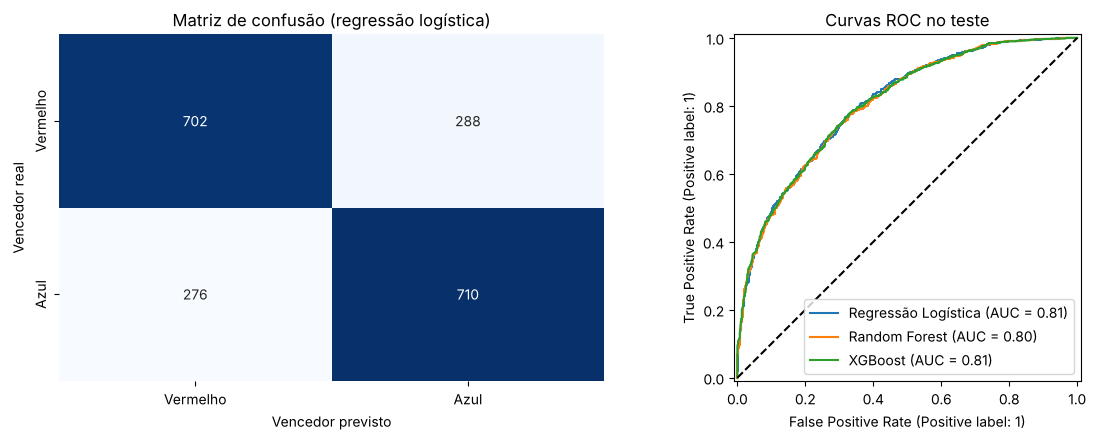

In [24]:
final = buscas['Regressão Logística']
pred_final = (probas['Regressão Logística'] >= 0.5).astype(int)
print(classification_report(y_test, pred_final, target_names=['Vermelho venceu', 'Azul venceu']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, pred_final), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Vermelho', 'Azul'], yticklabels=['Vermelho', 'Azul'])
axes[0].set_title('Matriz de confusão (regressão logística)'); axes[0].set_xlabel('Vencedor previsto'); axes[0].set_ylabel('Vencedor real')
for nome, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=nome, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--'); axes[1].set_title('Curvas ROC no teste')
plt.tight_layout(); plt.show()

No conjunto de teste, os três modelos ficam **empatados**: acurácia entre 71,5% e 72,1% e ROC-AUC entre 0,804 e 0,807. Com 1.976 partidas, o erro-padrão da acurácia é de cerca de 1 ponto percentual, então essas diferenças não significam nada. A **regra simples (apostar em quem tem mais ouro) acerta 71,8%**, igual aos modelos. Os resultados no teste ficaram um pouco abaixo da validação cruzada (73,7%), o que é normal numa amostra única: a estimativa honesta de desempenho é algo entre **71% e 74% de acurácia**.

A regressão logística, escolhida pela validação cruzada, erra de forma **equilibrada**: precisão e recall entre 0,71 e 0,72 para os dois times, sem favorecer o azul nem o vermelho. O F1-score é praticamente igual à acurácia (0,716), como esperado numa base balanceada.

Neste problema não há um tipo de erro mais grave que o outro (errar a vitória do azul ou a do vermelho tem o mesmo custo), por isso acurácia e ROC-AUC são as métricas adequadas.

### Em quais partidas o modelo é confiável?

,acurácia,partidas
faixa,,
50-60%,0.506,403
60-70%,0.594,406
70-80%,0.731,431
80-90%,0.839,416
90-100%,0.947,320


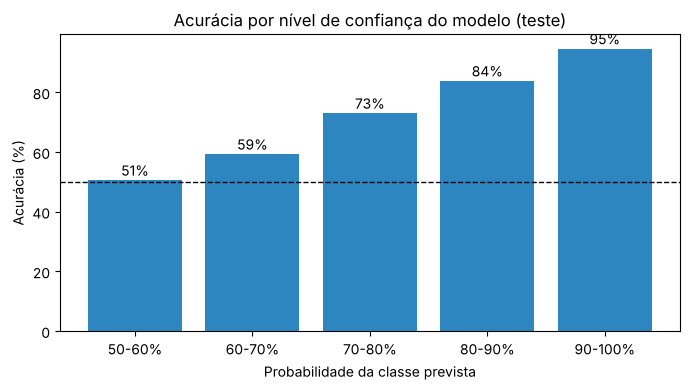

Partidas com confiança >= 80%: 37.2 %


In [25]:
conf = np.maximum(probas['Regressão Logística'], 1 - probas['Regressão Logística'])
faixa_conf = pd.cut(conf, [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], labels=['50-60%', '60-70%', '70-80%', '80-90%', '90-100%'])
conf_df = pd.DataFrame({'acerto': pred_final == y_test.values, 'faixa': faixa_conf}).groupby('faixa').acerto.agg(['mean', 'size'])
conf_df.columns = ['acurácia', 'partidas']
display(conf_df.round(3))
plt.figure(figsize=(7, 4))
plt.bar(conf_df.index.astype(str), conf_df['acurácia'] * 100, color='#2E86C1')
for i, v in enumerate(conf_df['acurácia'] * 100): plt.text(i, v + 1.5, f'{v:.0f}%', ha='center')
plt.axhline(50, color='black', linestyle='--', linewidth=1)
plt.title('Acurácia por nível de confiança do modelo (teste)'); plt.xlabel('Probabilidade da classe prevista'); plt.ylabel('Acurácia (%)')
plt.tight_layout(); plt.show()
print('Partidas com confiança >= 80%:', round((conf >= 0.8).mean() * 100, 1), '%')

O modelo **sabe quando está em dúvida**: quando a probabilidade prevista fica entre 50% e 60%, ele acerta só 51% das vezes, ou seja, é praticamente um palpite. Já quando passa de 80%, a acurácia sobe para 84% a 95%. Cerca de **37% das partidas** recebem uma previsão com confiança acima de 80%, e nessas o modelo é muito confiável. Isso é mais útil para o negócio do que olhar só a acurácia média de 71%.

# 8. Importância das variáveis

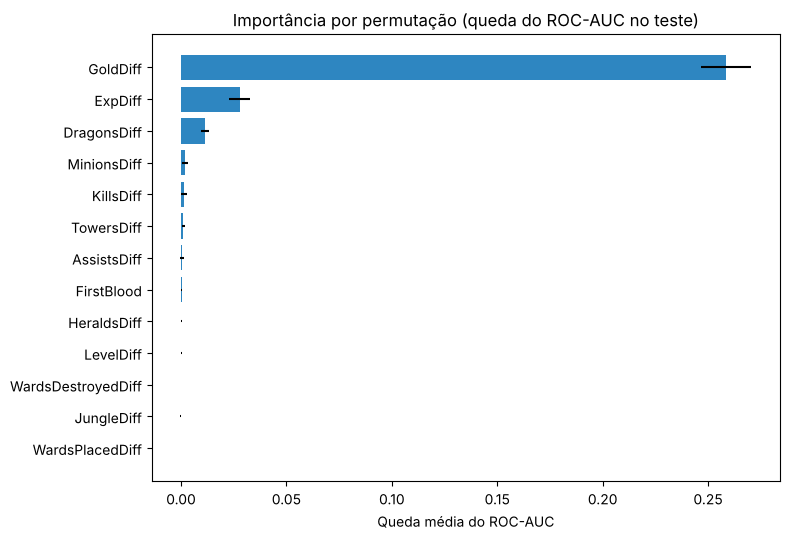

GoldDiff       0.2587
ExpDiff        0.0278
DragonsDiff    0.0114
MinionsDiff    0.0020
KillsDiff      0.0014
TowersDiff     0.0011
dtype: float64

In [26]:
imp = permutation_importance(final.best_estimator_, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=42)
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 5.5))
plt.barh(importancia.index, importancia.values, xerr=pd.Series(imp.importances_std, index=X.columns)[importancia.index].values, color='#2E86C1')
plt.title('Importância por permutação (queda do ROC-AUC no teste)'); plt.xlabel('Queda média do ROC-AUC')
plt.tight_layout(); plt.show()
importancia.sort_values(ascending=False).round(4).head(6)

In [27]:
pd.Series(final.best_estimator_.named_steps['model'].coef_[0], index=X.columns).sort_values(ascending=False).round(2)

GoldDiff              1.32
ExpDiff               0.45
DragonsDiff           0.29
FirstBlood            0.04
LevelDiff             0.03
HeraldsDiff           0.02
WardsDestroyedDiff    0.01
WardsPlacedDiff      -0.01
JungleDiff           -0.04
TowersDiff           -0.09
AssistsDiff          -0.10
KillsDiff            -0.16
MinionsDiff          -0.17
dtype: float64

**A importância das variáveis é dominada por uma só: o ouro.** Embaralhar `GoldDiff` derruba o ROC-AUC em 0,26, enquanto a segunda colocada (`ExpDiff`, experiência) derruba só 0,03 e a terceira (`DragonsDiff`) cerca de 0,01. As demais ficam perto de zero.

Os coeficientes da regressão logística (variáveis padronizadas) confirmam: ouro (+1,32), experiência (+0,45) e dragões (+0,29) aumentam a chance de vitória do azul. Os sinais negativos de abates (-0,16), assistências (-0,10), minions (-0,17) e torres (-0,09) **não significam que abater atrapalha**: como ouro e experiência já carregam quase toda essa informação (abates, minions e torres geram ouro), o modelo usa essas variáveis só para pequenos ajustes. É um efeito da correlação entre variáveis explicativas, por isso não interpreto os coeficientes pequenos isoladamente.

**Leitura pelo domínio do jogo:** o ouro compra itens e a experiência dá níveis, e juntos eles medem o quanto um time está mais forte que o outro. Todo o resto (abates, dragões, torres, minions) é o *caminho* para ganhar ouro e experiência. Por isso o modelo, ao ver o ouro, quase não precisa das outras variáveis. Já as sentinelas (visão) têm importância praticamente nula nos primeiros 10 minutos, o que é coerente com a EDA.

# 9. Recomendação de negócio

**Resumo para o negócio**

Consigo prever o vencedor de uma partida ranqueada aos 10 minutos com cerca de **72% de acurácia** (ROC-AUC 0,81), usando um modelo simples (regressão logística) que pode rodar ao vivo e ser explicado a qualquer pessoa. Modelos mais complexos (Random Forest, XGBoost) não ganharam nada: os três empataram.

**O que o dado mostra**

- O resultado aos 10 minutos depende quase só da **diferença de ouro**. Uma regra de uma linha ("o time com mais ouro vence") já acerta 72%.
- A partida **não está decidida** aos 10 minutos: com uma vantagem de ouro de 1500 a 3000, 21% dos jogos ainda são perdidos. Passando de 3000, 90% são vencidos.
- Objetivos como primeiro abate, dragão e torre aumentam a chance de vitória em 20 a 25 pontos percentuais, mas boa parte desse efeito já aparece no ouro e na experiência que eles geram.
- Vigiar o mapa (sentinelas) não muda o resultado dos primeiros 10 minutos.

**Recomendações**

1. **Transmissões e plataformas:** exibir a probabilidade de vitória ao vivo, mas **só destacá-la quando a confiança passa de 80%** (cerca de 37% das partidas), faixa em que o modelo acerta entre 84% e 95%. Abaixo de 70% de confiança a previsão é quase um palpite e não deve ser apresentada como certeza.
2. **Times e treinadores:** o foco dos 10 primeiros minutos deve ser ouro e experiência (farm, abates e objetivos que geram ouro), e não métricas isoladas como assistências ou sentinelas. Quem está atrás por menos de 1500 de ouro ainda tem a partida em aberto (a regra simples acerta só 53% a 66% nessa faixa) e deve jogar para virar, enquanto quem está com mais de 3000 de vantagem deve jogar com segurança.
3. **Produto de análise de partidas:** como a regra simples e o modelo completo têm o mesmo desempenho, a opção mais barata é começar pela regra de ouro e experiência. O modelo só se justifica se for usado para informar a confiança de cada previsão.

**Limitações e próximos passos**

- Os dados cobrem só os **10 primeiros minutos**; o jogo continua por mais 20 a 30 minutos, e a previsão tem um teto natural (~72%).
- Faltam variáveis que provavelmente explicam as viradas: **campeões escolhidos, composição do time, nível dos jogadores e posição no mapa**. Acrescentá-las é o caminho mais provável para ultrapassar os 72%.
- A base não informa o elo (nível dos jogadores) nem a versão (patch) do jogo, e os resultados podem mudar com atualizações.
- Seria útil repetir a análise com dados de outros minutos (5, 15, 20) para ver como a confiança cresce ao longo da partida.